# Wybór najlepszego modelu

In [38]:
import time

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    fbeta_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42

df = pd.read_csv("heart_disease_cleaned.csv")
df["target"] = (df["num"] > 0).astype(int)

thal_map = {"normal": 0, "reversable defect": 1, "fixed defect": 2}
df["chol_age"] = df["chol"] / df["age"]
df["thal_defect_severity"] = df["ca"] * df["thal"].map(thal_map)

print(df["target"].value_counts().sort_index().rename("Liczba pacjentów"))

target
0    411
1    508
Name: Liczba pacjentów, dtype: int64


## Podział danych

In [39]:
X = df.drop(columns=["id", "dataset", "num", "target"])
y = df["target"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, stratify=y, random_state=RANDOM_STATE
)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=RANDOM_STATE
)

## Porównanie modeli

In [40]:
categorical_features = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]
numeric_features = [col for col in X_train.columns if col not in categorical_features]

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ]
)

models = {
    "Regresja logistyczna": (
        LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
        {
            "classifier__C": [0.01, 0.1, 1, 10],
            "classifier__class_weight": [None, "balanced"],
        },
    ),
    "Drzewo decyzyjne": (
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        {
            "classifier__max_depth": [None, 3, 5, 8],
            "classifier__min_samples_leaf": [1, 3, 5],
            "classifier__class_weight": [None, "balanced"],
        },
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=RANDOM_STATE),
        {
            "classifier__n_estimators": [100, 200],
            "classifier__max_depth": [None, 5, 10],
            "classifier__min_samples_leaf": [1, 3],
            "classifier__class_weight": [None, "balanced"],
        },
    ),
    "Gradient Boosting": (
        GradientBoostingClassifier(random_state=RANDOM_STATE),
        {
            "classifier__n_estimators": [50, 100, 150],
            "classifier__learning_rate": [0.03, 0.1],
            "classifier__max_depth": [1, 2, 3],
            "classifier__min_samples_leaf": [1, 3],
        },
    ),
}

MIN_PRECISION = 0.80
searches = {}
model_rows = []

for name, (classifier, parameter_options) in models.items():
    pipeline = Pipeline(
        steps=[("preprocessing", preprocessor), ("classifier", classifier)]
    )
    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=parameter_options,
        n_iter=8,
        scoring={"Recall": "recall", "F1": "f1"},
        refit="Recall",
        cv=5,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
    search.fit(X_train, y_train)
    searches[name] = search

    best_index = search.best_index_
    best_cv_results = search.cv_results_
    prediction_start = time.perf_counter()
    valid_probabilities = search.best_estimator_.predict_proba(X_valid)[:, 1]
    prediction_time = time.perf_counter() - prediction_start
    valid_predictions = (valid_probabilities >= 0.5).astype(int)

    feasible_thresholds = []
    for step in range(5, 96):
        threshold = step / 100
        threshold_predictions = (valid_probabilities >= threshold).astype(int)
        threshold_precision = precision_score(
            y_valid, threshold_predictions, zero_division=0
        )
        if threshold_precision >= MIN_PRECISION:
            threshold_recall = recall_score(y_valid, threshold_predictions)
            threshold_f2 = fbeta_score(
                y_valid, threshold_predictions, beta=2, zero_division=0
            )
            feasible_thresholds.append(
                (
                    threshold_recall,
                    threshold_f2,
                    -threshold,
                    threshold,
                    threshold_precision,
                    threshold_predictions,
                )
            )
    if not feasible_thresholds:
        raise ValueError(f"Brak progu spełniającego Precision >= {MIN_PRECISION:.0%} dla {name}.")

    valid_recall_at_threshold, valid_f2_at_threshold, _, valid_threshold, valid_precision_at_threshold, tuned_valid_predictions = max(
        feasible_thresholds, key=lambda row: (row[0], row[1], row[2])
    )

    model_rows.append(
        {
            "Model": name,
            "Recall CV": best_cv_results["mean_test_Recall"][best_index],
            "Odch. Recall CV": best_cv_results["std_test_Recall"][best_index],
            "F1 CV": best_cv_results["mean_test_F1"][best_index],
            "Accuracy 0.5": accuracy_score(y_valid, valid_predictions),
            "Precision 0.5": precision_score(y_valid, valid_predictions, zero_division=0),
            "Recall 0.5": recall_score(y_valid, valid_predictions),
            "F1 0.5": f1_score(y_valid, valid_predictions, zero_division=0),
            "ROC-AUC": roc_auc_score(y_valid, valid_probabilities),
            "PR-AUC": average_precision_score(y_valid, valid_probabilities),
            "Próg (Precision >= 80%)": valid_threshold,
            "Precision przy progu": valid_precision_at_threshold,
            "Recall przy progu": valid_recall_at_threshold,
            "F2 przy progu": valid_f2_at_threshold,
            "Czas predykcji (ms)": prediction_time * 1000,
        }
    )

model_results = pd.DataFrame(model_rows).sort_values(
    ["Recall CV", "F1 CV", "Odch. Recall CV"],
    ascending=[False, False, True],
).reset_index(drop=True)
print(model_results.round(3))

                  Model  Recall CV  Odch. Recall CV  F1 CV  Accuracy 0.5  \
0     Gradient Boosting      0.869            0.033  0.867         0.848   
1  Regresja logistyczna      0.869            0.040  0.851         0.837   
2         Random Forest      0.859            0.054  0.861         0.859   
3      Drzewo decyzyjne      0.807            0.054  0.811         0.772   

   Precision 0.5  Recall 0.5  F1 0.5  ROC-AUC  PR-AUC  \
0          0.854       0.871   0.863    0.919   0.918   
1          0.859       0.842   0.850    0.892   0.901   
2          0.887       0.851   0.869    0.933   0.943   
3          0.792       0.792   0.792    0.825   0.814   

   Próg (Precision >= 80%)  Precision przy progu  Recall przy progu  \
0                     0.30                 0.825              0.931   
1                     0.40                 0.800              0.871   
2                     0.31                 0.807              0.950   
3                     0.55                 0.823 

In [41]:
print(pd.DataFrame({
    "Model": list(models),
    "Zakres i uzasadnienie strojenia": [
        "C = 0.01–10 sprawdza siłę regularyzacji w skali logarytmicznej; class_weight porównuje zwykłe uczenie z wyrównaniem klas.",
        "Głębokość i minimalna liczba próbek liścia ograniczają złożoność drzewa; class_weight sprawdza wpływ kosztu klas.",
        "Liczba drzew równoważy stabilność i czas; głębokość, wielkość liścia i class_weight kontrolują złożoność oraz balans klas.",
        "Liczba drzew, learning_rate, głębokość i wielkość liścia kontrolują tempo uczenia oraz złożoność kolejnych poprawek.",
    ],
}))

print(pd.DataFrame({
    "Metryka": ["PR-AUC"],
    "Uzasadnienie": [
        "Pokazuje kompromis precision-recall dla klasy chorej i jest szczególnie użyteczna przy niezbalansowanych klasach. Raportujemy ją obok ROC-AUC; w tym zbiorze klasy są umiarkowanie zbalansowane (55,3% chorych)."
    ],
}))

                  Model                    Zakres i uzasadnienie strojenia
0  Regresja logistyczna  C = 0.01–10 sprawdza siłę regularyzacji w skal...
1      Drzewo decyzyjne  Głębokość i minimalna liczba próbek liścia ogr...
2         Random Forest  Liczba drzew równoważy stabilność i czas; głęb...
3     Gradient Boosting  Liczba drzew, learning_rate, głębokość i wielk...
  Metryka                                       Uzasadnienie
0  PR-AUC  Pokazuje kompromis precision-recall dla klasy ...


## Finalny model

Wybrany model: Gradient Boosting
Najlepsze hiperparametry: {'classifier__n_estimators': 100, 'classifier__min_samples_leaf': 1, 'classifier__max_depth': 3, 'classifier__learning_rate': 0.1}
Średni Recall CV: 0.869
Odchylenie Recall CV: 0.033
   Accuracy test  Precision test  Recall test  F1 test  ROC-AUC test  \
0          0.875           0.891        0.882    0.887         0.952   

   PR-AUC test  Czas predykcji test (ms)  
0        0.962                     8.635  


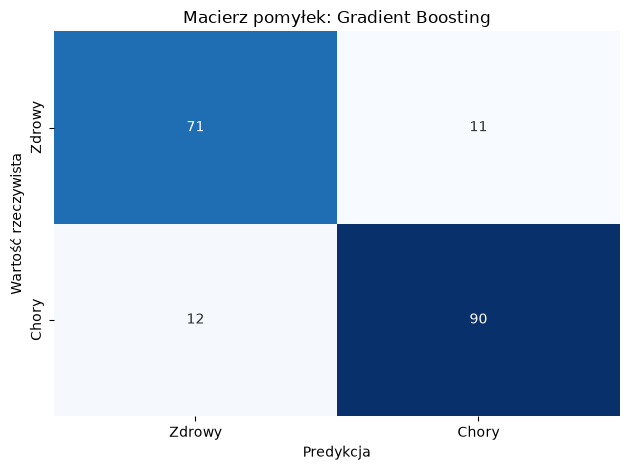

                            Cecha  Ważność
3                 numeric__thalch    0.034
1               numeric__trestbps    0.038
22   categorical__slope_upsloping    0.050
5               numeric__chol_age    0.065
2                   numeric__chol    0.075
4                numeric__oldpeak    0.082
6   numeric__thal_defect_severity    0.109
9    categorical__cp_asymptomatic    0.110
23            categorical__ca_0.0    0.112
28       categorical__thal_normal    0.218


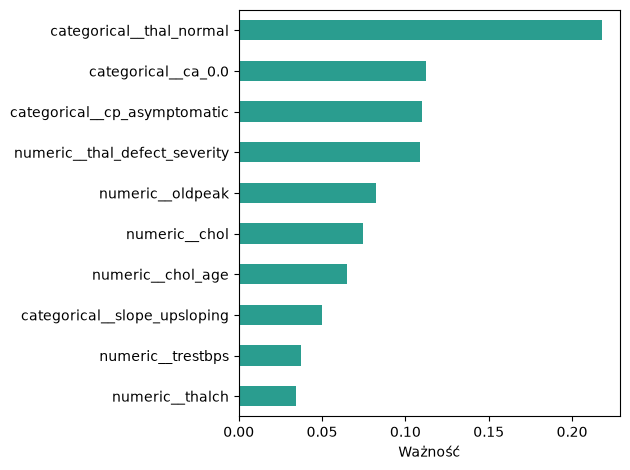

In [42]:
best_model_name = model_results.loc[0, "Model"]
best_search = searches[best_model_name]
best_model = best_search.best_estimator_
test_start = time.perf_counter()
test_probabilities = best_model.predict_proba(X_test)[:, 1]
test_prediction_time = (time.perf_counter() - test_start) * 1000
test_predictions = (test_probabilities >= 0.5).astype(int)

print(f"Wybrany model: {best_model_name}")
print(f"Najlepsze hiperparametry: {best_search.best_params_}")
print(f"Średni Recall CV: {model_results.loc[0, 'Recall CV']:.3f}")
print(f"Odchylenie Recall CV: {model_results.loc[0, 'Odch. Recall CV']:.3f}")
print(
    pd.DataFrame(
        [{
            "Accuracy test": accuracy_score(y_test, test_predictions),
            "Precision test": precision_score(y_test, test_predictions, zero_division=0),
            "Recall test": recall_score(y_test, test_predictions),
            "F1 test": f1_score(y_test, test_predictions, zero_division=0),
            "ROC-AUC test": roc_auc_score(y_test, test_probabilities),
            "PR-AUC test": average_precision_score(y_test, test_probabilities),
            "Czas predykcji test (ms)": test_prediction_time,
        }]
    ).round(3)
)

sns.heatmap(
    confusion_matrix(y_test, test_predictions, labels=[0, 1]),
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Zdrowy", "Chory"],
    yticklabels=["Zdrowy", "Chory"],
)
plt.title(f"Macierz pomyłek: {best_model_name}")
plt.xlabel("Predykcja")
plt.ylabel("Wartość rzeczywista")
plt.tight_layout()
plt.show()

final_classifier = best_model.named_steps["classifier"]
if hasattr(final_classifier, "feature_importances_"):
    importance_values = final_classifier.feature_importances_
else:
    importance_values = abs(final_classifier.coef_[0])

feature_names = best_model.named_steps["preprocessing"].get_feature_names_out()
top_features = (
    pd.DataFrame({"Cecha": feature_names, "Ważność": importance_values})
    .sort_values("Ważność", ascending=False)
    .head(10)
    .sort_values("Ważność")
)
print(top_features.round(3))
top_features.plot.barh(x="Cecha", y="Ważność", legend=False, color="#2a9d8f")
plt.xlabel("Ważność")
plt.ylabel("")
plt.tight_layout()
plt.show()

top_feature_names = top_features.sort_values("Ważność", ascending=False)["Cecha"].head(3).tolist()

In [43]:
test_model_rows = []
for name, search in searches.items():
    model_threshold = model_results.loc[
        model_results["Model"] == name, "Próg (Precision >= 80%)"
    ].iloc[0]
    probabilities = search.best_estimator_.predict_proba(X_test)[:, 1]
    predictions = (probabilities >= model_threshold).astype(int)
    test_model_rows.append({
        "Model": name,
        "Próg z walidacji": model_threshold,
        "Accuracy test": accuracy_score(y_test, predictions),
        "Precision test": precision_score(y_test, predictions, zero_division=0),
        "Recall test": recall_score(y_test, predictions),
        "F1 test": f1_score(y_test, predictions, zero_division=0),
        "F2 test": fbeta_score(y_test, predictions, beta=2, zero_division=0),
        "ROC-AUC test": roc_auc_score(y_test, probabilities),
        "PR-AUC test": average_precision_score(y_test, probabilities),
    })

test_model_comparison = pd.DataFrame(test_model_rows).sort_values(
    "Recall test", ascending=False
).reset_index(drop=True)
print(test_model_comparison.round(3))

                  Model  Próg z walidacji  Accuracy test  Precision test  \
0         Random Forest              0.31          0.864           0.813   
1     Gradient Boosting              0.30          0.886           0.872   
2  Regresja logistyczna              0.40          0.815           0.783   
3      Drzewo decyzyjne              0.55          0.793           0.864   

   Recall test  F1 test  F2 test  ROC-AUC test  PR-AUC test  
0        0.980    0.889    0.942         0.949        0.957  
1        0.931    0.900    0.919         0.952        0.962  
2        0.922    0.847    0.890         0.905        0.925  
3        0.745    0.800    0.766         0.822        0.818  


In [47]:
random_forest_row = model_results.loc[model_results["Model"] == "Random Forest"].iloc[0]
gradient_boosting_row = model_results.loc[model_results["Model"] == "Gradient Boosting"].iloc[0]
test_random_forest_row = test_model_comparison.loc[test_model_comparison["Model"] == "Random Forest"].iloc[0]
test_gradient_boosting_row = test_model_comparison.loc[test_model_comparison["Model"] == "Gradient Boosting"].iloc[0]
print(pd.DataFrame({
    "Porównanie wyboru": [
        f"Gradient Boosting: Recall CV = {gradient_boosting_row['Recall CV']:.3f} ± {gradient_boosting_row['Odch. Recall CV']:.3f}; Random Forest: {random_forest_row['Recall CV']:.3f} ± {random_forest_row['Odch. Recall CV']:.3f}.",
        f"Przy progach z walidacji oba modele spełniają Precision >= 0,80; na teście Recall wyniósł {test_gradient_boosting_row['Recall test']:.3f} dla Gradient Boosting i {test_random_forest_row['Recall test']:.3f} dla Random Forest.",
        f"Gradient Boosting ma wyższe testowe Accuracy ({test_gradient_boosting_row['Accuracy test']:.3f} vs {test_random_forest_row['Accuracy test']:.3f}), Precision ({test_gradient_boosting_row['Precision test']:.3f} vs {test_random_forest_row['Precision test']:.3f}) oraz PR-AUC ({test_gradient_boosting_row['PR-AUC test']:.3f} vs {test_random_forest_row['PR-AUC test']:.3f}); Random Forest wykrył więcej chorych.",
        f"Wybór pozostaje oparty na Recall CV, jego stabilności i jakości rankingu PR-AUC; pomiar predykcji Gradient Boosting był krótszy ({gradient_boosting_row['Czas predykcji (ms)']:.1f} ms vs {random_forest_row['Czas predykcji (ms)']:.1f} ms na walidacji).",
    ],
}))

                                   Porównanie wyboru
0  Gradient Boosting: Recall CV = 0.869 ± 0.033; ...
1  Przy progach z walidacji oba modele spełniają ...
2  Gradient Boosting ma wyższe testowe Accuracy (...
3  Wybór pozostaje oparty na Recall CV, jego stab...


In [45]:
feature_notes = {
    "numeric__thalch": "Maksymalne tętno osiągnięte podczas wysiłku.",
    "numeric__trestbps": "Ciśnienie tętnicze w spoczynku.",
    "categorical__slope_upsloping": "Kierunek nachylenia odcinka ST podczas wysiłku.",
    "numeric__chol_age": "Cholesterol całkowity odniesiony do wieku pacjenta.",
    "numeric__chol": "Stężenie cholesterolu całkowitego.",
    "numeric__oldpeak": "Obniżenie odcinka ST wywołane wysiłkiem.",
    "numeric__thal_defect_severity": "Inżynierski iloczyn liczby naczyń i zakodowanej kategorii thal.",
    "categorical__cp_asymptomatic": "Kategoria bólu w klatce piersiowej: bezobjawowa.",
    "categorical__ca_0.0": "Brak uwidocznionych dużych naczyń w kategorii ca.",
    "categorical__thal_normal": "Prawidłowa kategoria wyniku badania thal.",
}
feature_interpretation = top_features.copy()
feature_interpretation["Znaczenie"] = feature_interpretation["Cecha"].map(feature_notes)
print(feature_interpretation.round(3))
print(pd.DataFrame({
    "Wniosek": [
        "Najważniejsze cechy odpowiadają pomiarom klinicznym i wynikom badań, więc ich znaczenie predykcyjne jest wiarygodne jako kierunek do dalszej analizy. Ważność modelu nie oznacza związku przyczynowego.",
    ],
}))

                            Cecha  Ważność  \
3                 numeric__thalch    0.034   
1               numeric__trestbps    0.038   
22   categorical__slope_upsloping    0.050   
5               numeric__chol_age    0.065   
2                   numeric__chol    0.075   
4                numeric__oldpeak    0.082   
6   numeric__thal_defect_severity    0.109   
9    categorical__cp_asymptomatic    0.110   
23            categorical__ca_0.0    0.112   
28       categorical__thal_normal    0.218   

                                            Znaczenie  
3        Maksymalne tętno osiągnięte podczas wysiłku.  
1                     Ciśnienie tętnicze w spoczynku.  
22    Kierunek nachylenia odcinka ST podczas wysiłku.  
5   Cholesterol całkowity odniesiony do wieku pacj...  
2                  Stężenie cholesterolu całkowitego.  
4            Obniżenie odcinka ST wywołane wysiłkiem.  
6   Inżynierski iloczyn liczby naczyń i zakodowane...  
9    Kategoria bólu w klatce piersiowej: bezo